# MASF: Kolmogorov flow (128 x 128, speed)

Load the pretrained checkpoint from Hugging Face and run filtering with online fine-tuning. Figures are saved to `outputs/kolmogorov_128_speed/`.

In [1]:
import os, sys, glob
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import Image, display
from huggingface_hub import snapshot_download

REPO = os.path.abspath("..")
sys.path.insert(0, REPO)
OUT = "outputs/kolmogorov_128_speed"
os.makedirs(f"{OUT}/ckpt", exist_ok=True)
device = "cuda" if torch.cuda.is_available() else "cpu"

## Checkpoint and data

In [2]:
snapshot_download("eunbii1/masf", local_dir=REPO, allow_patterns="checkpoints/kolmogorov_128/speed.pt")
snapshot_download("eunbii1/masf", repo_type="dataset", local_dir=REPO, allow_patterns="datasets/kolmogorov/dim128_num_samples1000/*")

Fetching 1 files:   0%|          | 0/1 [00:00<?, ?it/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

'/home/users/eunbiyoon6286/masf/masf_official_tests/cs_verify/repo'

In [3]:
from utils.run_utils import load_yaml, set_seed, measurement_update, time_update
from utils.build import build_steps, build_dynamics, build_measurement, build_method, build_dataset
from utils.summary import finalize_and_save
from utils.train_load import load_trained_model

cfg = load_yaml(f"{REPO}/configs/kolmogorov_128/speed.yaml")
cfg["system"]["device"] = device
cfg["system"]["seed"] = 43
set_seed(cfg)

steps, total_step = build_steps(cfg)
dynamics, measurement, method = build_dynamics(cfg), build_measurement(cfg), build_method(cfg)
prior, truth, total_obs, obs = build_dataset(cfg, dynamics, measurement, steps)

[DATASET] prior (10, 2, 128, 128) trajectory (51, 2, 128, 128) dir /home/users/eunbiyoon6286/masf/masf_official_tests/cs_verify/repo/datasets/kolmogorov/dim128_num_samples1000


## Filtering

At the first step the pretrained checkpoint is loaded. At every measurement step the model is fine-tuned on the prior ensemble before sampling the posterior.

In [4]:
states = torch.empty((len(truth), *prior.shape), device=device)
for k, i in enumerate(steps):
    model = load_trained_model(cfg, method, measurement, dynamics, i, k, steps, prior, device, OUT)
    posterior = measurement_update(method, cfg, model, measurement, i, total_step, prior, obs, device)
    prior, states = time_update(dynamics, posterior, k, steps, total_step, states)

rmse, _ = finalize_and_save(cfg, OUT, dynamics, truth, obs, total_obs, states, steps, total_step)
print("RMSE", rmse)

[INIT] step 0 initialized from pretrained
pretrain path: /home/users/eunbiyoon6286/masf/masf_official_tests/cs_verify/repo/checkpoints/kolmogorov_128/speed.pt
[DATASET for pretraining] prior (1000, 2, 128, 128) dir /home/users/eunbiyoon6286/masf/masf_official_tests/cs_verify/repo/datasets/kolmogorov/dim128_num_samples1000


pretrained model is loaded...
50 th step training...


train(step=50):   0%|          | 0/120 [00:00<?, ?it/s]

train(step=50):  94%|█████████▍| 113/120 [00:05<00:00, 22.53it/s, epoch=113, train=0.642, train_x=0.00673, train_h=0.635]

60 th step training...


train(step=60):   0%|          | 0/120 [00:00<?, ?it/s]

... (7 outputs left out)

100 th step training...


train(step=100):   0%|          | 0/120 [00:00<?, ?it/s]

[saved] outputs/kolmogorov_128_speed/vorticity_pairs.gif (frames=51, fps=4)
RMSE 0.23028126472773025 FCRPS 0.11097883342783961 SSR 1.0211834842695582


RMSE 0.23028126472773025


## Results

Vorticity of the ground truth, the posterior mean and the measurement at every step, and the RMSE curve.

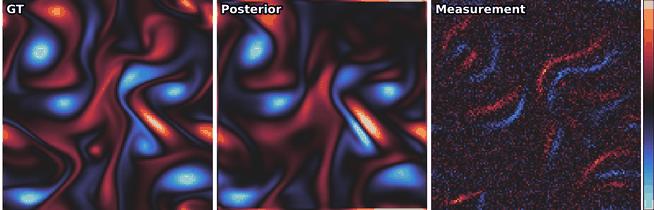

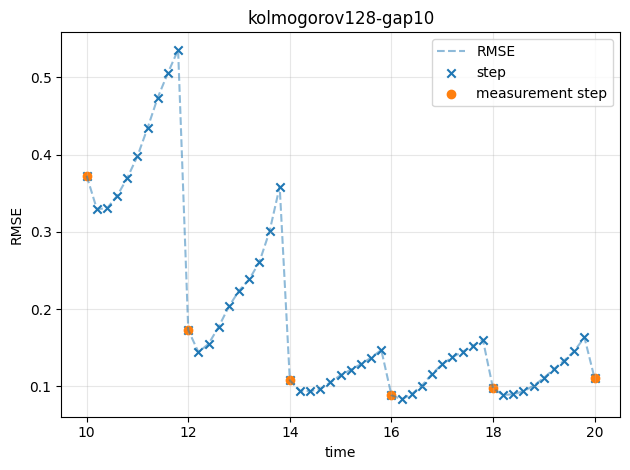

In [5]:
from PIL import Image as PImage, ImageSequence

frames = [f.convert("RGB").resize((f.width // 2, f.height // 2), PImage.LANCZOS) for f in ImageSequence.Iterator(PImage.open(f"{OUT}/vorticity_pairs.gif"))][::2]
frames[0].save(f"{OUT}/vorticity_small.gif", save_all=True, append_images=frames[1:], duration=500, loop=0)
display(Image(filename=f"{OUT}/vorticity_small.gif"))
display(Image(filename=glob.glob(f"{OUT}/RMSE_mean*.png")[0]))